# EN3160 Image Processing and Machine Vision
## Assignment 3: Neural Networks
GUNATHUNGA U.A.  
230218G  
[GitHub repository](https://github.com/Upani-Gunathunga/EN3160-A3-Neural-Networks)


In [16]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import copy
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

output_path = Path('results')
output_path.mkdir(exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)
print('Device:', device)
print('PyTorch:', torch.__version__)
print('Torchvision:', torchvision.__version__)
print('Working folder:', Path.cwd())


Device: cuda
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Working folder: c:\Users\asus\Documents\semester 5\CV\ass3


## QUESTION 1
### Important parts of code

The complete Question 1 follows the six sections of Listing 1 with below changes.

| Change | Meaning |
|---|---|
| Middle layer | $3072\rightarrow100\rightarrow10$. Weight shapes are $3072\times100$ and $100\times10$. |
| Sigmoid | Apply $1/(1+e^{-z})$ to the 100 hidden values. |
| Cross-entropy | Use softmax class probabilities and $L=-\frac1N\sum_i\log P_{i,y_i}$. `log_softmax` computes the log probabilities directly. |
| Backpropagation | The output gradient is $(P-Y)/N$. The hidden gradient also includes the sigmoid derivative $a(1-a)$. Compute all gradients before updating weights. |
| Epoch count | Change 20 to 10. Final accuracies use the weights after epoch 10. |


Weight initialization uses standard deviation $1/\sqrt{\text{input count}}$. The learning rate is 0.1 with decay 0.9.


Device: cuda
Epoch 1/10, Loss: 1.8062101985216141
Epoch 2/10, Loss: 1.6728562210798263
Epoch 3/10, Loss: 1.6113708715438844
Epoch 4/10, Loss: 1.566626722574234
Epoch 5/10, Loss: 1.5266632050275804
Epoch 6/10, Loss: 1.491914845585823
Epoch 7/10, Loss: 1.463333183646202
Epoch 8/10, Loss: 1.4365388722419739
Epoch 9/10, Loss: 1.4133375564813613
Epoch 10/10, Loss: 1.3922812718749047


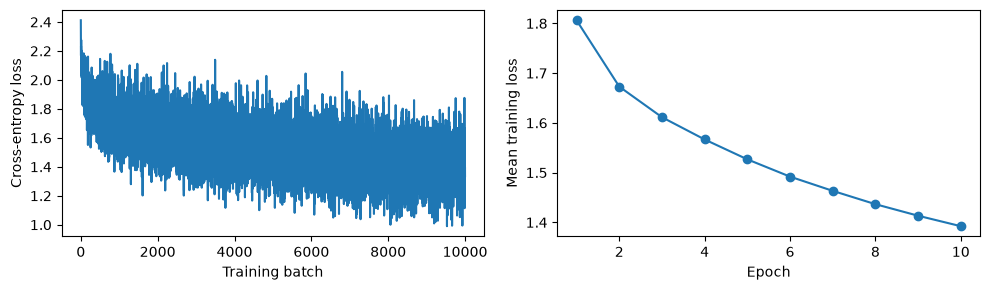

Training accuracy: 53.45%
Test accuracy: 47.77%


In [17]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
print('Device:', device)

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
# std = 1e-5       # Unused with current initialization

# w = torch.randn(Din, K) * std  # One layer: directly map input to output
# b = torch.zeros(K)
########################################

H = 100
# Initialize weights and biases
w1 = torch.randn(Din, H, device=device) / (Din ** 0.5)
b1 = torch.zeros(H, device=device)
w2 = torch.randn(H, K, device=device) / (H ** 0.5)
b2 = torch.zeros(K, device=device)
##########################################

# Hyperparameters
iterations = 10
lr = 0.1          # Learning rate
lr_decay = 0.9    # Learning rate decay
reg = 0           # Regularization
loss_history = []
epoch_losses = []


# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        #-----------move batch to device----------
        inputs = inputs.to(device)
        labels = labels.to(device)
       
        Ntr = inputs.shape[0]  # Batch size

        # x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        # y_train_onehot = nn.functional.one_hot(labels, K).float()

        #-----------input notation----------
        x1 = inputs.view(Ntr, -1)
        y = nn.functional.one_hot(labels, K).float()
       

        ############### middle layer and sigmoid activation #######

        # Forward pass
        # y_pred = x_train.mm(w) + b  # Output layer activation

        # hidden_input = x_train.mm(w1) + b1
        # hidden = torch.sigmoid(hidden_input)
        # y_pred = hidden.mm(w2) + b2
        # log_probs = torch.log_softmax(y_pred, dim=1)

        #-----------forward pass 
        a1 = x1 @ w1 + b1
        a2 = torch.sigmoid(a1)
        a3 = a2 @ w2 + b2

        log_yhat = torch.log_softmax(a3, dim=1)
        yhat = log_yhat.exp()
        #-------------------------------------

        # Loss calculation (log likelihood with regularization)

        # loss = -(y_train_onehot * log_probs).sum() / Ntr
        # loss = loss + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

        # loss_history.append(loss.item())
        # running_loss += loss.item()

        #-----------cross-entropy loss----------
        L = -(y * log_yhat).sum() / Ntr
        L = L + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

        loss_history.append(L.item())
        running_loss += L.item()
        #-------------------------------------

        # Backpropagation
        # dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        # dw = x_train.t().mm(dy_pred) + reg * w
        # db = dy_pred.sum(dim=0)

        # Parameter update
        # w -= lr * dw
        # b -= lr * db

        # Backpropagation removed
        # probs = log_probs.exp()
        # dy_pred = (probs - y_train_onehot) / Ntr
        # dw2 = hidden.t().mm(dy_pred) + 2 * reg * w2
        # db2 = dy_pred.sum(dim=0)
        # d_hidden = dy_pred.mm(w2.t())
        # d_hidden_input = d_hidden * hidden * (1 - hidden)
        # dw1 = x_train.t().mm(d_hidden_input) + 2 * reg * w1
        # db1 = d_hidden_input.sum(dim=0)

        # Parameter update removed
        # w1 -= lr * dw1
        # b1 -= lr * db1
        # w2 -= lr * dw2
        # b2 -= lr * db2

        #-----------backpropagation ----------

        #  Output score gradients
        dL_da3 = (yhat - y) / Ntr

        # Output weights and biases
        dL_dw2 = a2.T @ dL_da3 + 2 * reg * w2
        dL_db2 = dL_da3.sum(dim=0)

        #  Hidden activation gradients
        dL_da2 = dL_da3 @ w2.T

        # sigmoid
        dL_da1 = dL_da2 * a2 * (1 - a2)

        #  Input weights and biases
        dL_dw1 = x1.T @ dL_da1 + 2 * reg * w1
        dL_db1 = dL_da1.sum(dim=0)

        # Parameter update
        w1 -= lr * dL_dw1
        b1 -= lr * dL_db1
        w2 -= lr * dL_dw2
        b2 -= lr * dL_db2
        #-----------------------

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    epoch_losses.append(running_loss / len(trainloader))

    # Learning rate decay
    lr *= lr_decay


# 4. Plotting the Loss History
# Commented because the next figure includes it
# plt.plot(loss_history)
# plt.title("Loss History")
# plt.xlabel("Iteration")
# plt.ylabel("Loss")
# plt.show()

# 4. Plotting the Loss History
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(loss_history)
axes[0].set_xlabel('Training batch')
axes[0].set_ylabel('Cross-entropy loss')

axes[1].plot(range(1, iterations + 1), epoch_losses, marker='o')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean training loss')

plt.tight_layout()
plt.show()


# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        Ntr = inputs.shape[0]

        # x_train = inputs.view(Ntr, -1)
        # y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        #-----------middle layer and sigmoid activation----------
        # hidden_input = x_train.mm(w1) + b1
        # hidden = torch.sigmoid(hidden_input)
        # y_train_pred = hidden.mm(w2) + b2
        #--------------end------------------------

        #_train_pred = x_train.mm(w) + b
        # predicted_train = torch.argmax(y_train_pred, dim=1)

        #-----------forward pass with new notation----------
        x1 = inputs.view(Ntr, -1)
        a1 = x1 @ w1 + b1
        a2 = torch.sigmoid(a1)
        a3 = a2 @ w2 + b2

        # Scores suffice for choosing the class
        predicted_train = torch.argmax(a3, dim=1)
        #--------------end------------------------

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")


# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        Nte = inputs.shape[0]

        # x_test = inputs.view(Nte, -1)
        # y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        #-----------middle layer and sigmoid activation----------
        # hidden_input = x_test.mm(w1) + b1
        # hidden = torch.sigmoid(hidden_input)
        # y_test_pred = hidden.mm(w2) + b2
        #--------------end------------------------

        #_test_pred = x_test.mm(w) + b
        # predicted_test = torch.argmax(y_test_pred, dim=1)

        #-----------forward pass with new notation----------
        x1 = inputs.view(Nte, -1)
        a1 = x1 @ w1 + b1
        a2 = torch.sigmoid(a1)
        a3 = a2 @ w2 + b2

        # Scores suffice for choosing the class
        predicted_test = torch.argmax(a3, dim=1)
        #--------------end------------------------

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

In [18]:
#-----------results and comparison----------
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

output_path = Path('results')
output_path.mkdir(exist_ok=True)
q1_results = pd.DataFrame({
    'Split': ['Training', 'Test'],
    'Correct': [correct_train, correct_test],
    'Total': [total_train, total_test],
    'Accuracy (%)': [train_acc, test_acc]
})
display(q1_results)
q1_results.to_csv(output_path / 'q1_results.csv', index=False)
pd.DataFrame({'epoch': range(1, iterations + 1), 'loss': epoch_losses}).to_csv(
    output_path / 'q1_epoch_losses.csv', index=False)
gap = train_acc - test_acc
display(Markdown(
    f'After {iterations} epochs, training accuracy is {train_acc:.2f}% and '
    f'test accuracy is {test_acc:.2f}%.  \n'
    f'The train minus test gap is {gap:.2f} percentage points.  \n'
    f'Mean training-batch loss changed from {epoch_losses[0]:.4f} '
    f'to {epoch_losses[-1]:.4f}.'))
#--------------end------------------------

,Split,Correct,Total,Accuracy (%)
0,Training,26724,50000,53.448
1,Test,4777,10000,47.770


After 10 epochs, training accuracy is 53.45% and test accuracy is 47.77%.  
The train minus test gap is 5.68 percentage points.  
Mean training-batch loss changed from 1.8062 to 1.3923.

### Image results and comparison of results
The plot shows cross-entropy after each training batch. An epoch is one complete pass through the training set.  
The table reports final training and test accuracies. A positive train minus test gap means the model classified the training images more accurately.  
The epoch loss averages batches while weights are being updated. The final accuracies are measured afterward with fixed weights. 
Model flattens images and uses one hidden layer, so it has limited capacity compared with a CNN, so accuracy is not very high.
The sigmoid hidden layer allows nonlinear classification. Flattening the image does not  preserve its two-dimensional layout.

## QUESTION 2
### Important parts of code


In [4]:
#fixed

transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
batch_size = 50
trainset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform)
train_eval_loader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=False, num_workers=0)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0)
#--------------------------------------
print('Train:', len(trainset), 'Test:', len(testset))
print('Image shape:', tuple(trainset[0][0].shape))


Train: 60000 Test: 10000
Image shape: (1, 32, 32)


#### 2(a)
The network follows the LeNet-5 layout in lecture slides. Tanh provides the nonlinearity.

| Step | Output per image |
|---|---|
| Padded MNIST input | $1\times32\times32$ |
| 5 by 5 convolution and tanh | $6\times28\times28$ |
| Average pooling | $6\times14\times14$ |
| 5 by 5 convolution and tanh | $16\times10\times10$ |
| Average pooling | $16\times5\times5$ |
| Fully connected layers | $400\rightarrow120\rightarrow84\rightarrow10$ |



In [5]:
#  from lec slides lenet5

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.Conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.Conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.tanh(self.Conv1(x))
        x = nn.functional.avg_pool2d(x, kernel_size=2, stride=2)
        x = torch.tanh(self.Conv2(x))
        x = nn.functional.avg_pool2d(x, kernel_size=2, stride=2)
        x = x.view(-1, 16*5*5)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.fc3(x)
        return x
#--------------------------------------


#### 2(b)

In [ ]:

class SmallCNN(nn.Module):
#--------------- from https://github.com/chabi1773/EN3150_Assignment_03_Team-FrameX.git where i implemented a modified vgg16+lenet architecture------------------
    def __init__(self):
        super().__init__()
        self.Conv1 = nn.Conv2d(1,6,kernel_size=3,stride=1,padding=1)#maxpooling doesnt change the cin or cout.. only downsample the picture
        self.batch_norm1 = nn.BatchNorm2d(6)
        self.Conv2 = nn.Conv2d(6,16,kernel_size=3,stride=1,padding=1)
        self.batch_norm2 = nn.BatchNorm2d(16)

        # Added third convolution and dropout before fc
        self.Conv3 = nn.Conv2d(16,16,kernel_size=3,stride=1,padding=1)
        self.batch_norm3 = nn.BatchNorm2d(16)
        self.dropout = nn.Dropout(0.25)

        self.fc1    = nn.Linear(16*4*4,120)
        self.fc2    = nn.Linear(120,84)
        self.fc3    = nn.Linear(84,10)

        
    def forward(self,x):
        x = torch.relu(self.batch_norm1(self.Conv1(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = torch.relu(self.batch_norm2(self.Conv2(x)))
        x = torch.max_pool2d(x,kernel_size=2,stride=2)

        # Added third convolution
        x = torch.relu(self.batch_norm3(self.Conv3(x)))

        x = torch.max_pool2d(x,kernel_size=2,stride=2)
        x = x.view(-1,16*4*4)

        # Added dropout
        x = self.dropout(x)

        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)

        return x


### 02 (c)

In [ ]:

def train_epoch(model, loader, optimizer1, criterion, frozen=False):
    model.train()
    if frozen:
        model.eval()
        model.fc.train()
    loss_sum = 0.0
    total = 0
    for images, label in loader:
        images, label = images.to(device), label.to(device)
        
        #----------------
        output = model(images)
        loss = criterion(output, label)
        optimizer1.zero_grad()
        loss.backward()
        optimizer1.step()
        #--------------------------------------
        loss_sum += loss.item() * label.size(0)
        total += label.size(0)
    return loss_sum / total
#--------------------------------------


In [ ]:
# Added loss
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    all_labels = []
    all_predictions = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            output = model(images)
            loss = criterion(output, labels)
            predicted = output.argmax(dim=1)
            loss_sum += loss.item() * labels.size(0)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predicted.cpu().tolist())
    return loss_sum / total, 100 * correct / total, all_labels, all_predictions


In [9]:
# Added per-epoch result collection
def fit_model(model, trainloader, train_eval_loader, eval_loader,
              optimizer, epochs, frozen=False, scheduler=None):
    criterion = nn.CrossEntropyLoss()
    history = []
    start = time.time()
    for epoch in range(epochs):
        update_loss = train_epoch(model, trainloader, optimizer, criterion, frozen)
        train_loss, train_acc, _, _ = evaluate(model, train_eval_loader, criterion)
        eval_loss, eval_acc, _, _ = evaluate(model, eval_loader, criterion)
        history.append([epoch + 1, train_loss, eval_loss, train_acc, eval_acc])
        print(f'Epoch {epoch + 1:2d} | train loss {train_loss:.4f} | '
              f'eval loss {eval_loss:.4f} | train {train_acc:.2f}% | eval {eval_acc:.2f}%')
        if scheduler is not None:
            scheduler.step()
    elapsed = time.time() - start
    names = ['epoch', 'train_loss', 'eval_loss', 'train_accuracy', 'eval_accuracy']
    return pd.DataFrame(history, columns=names), elapsed


In [14]:
q2_models = {}
q2_results = {}
q2_times = {}
for name in ['LeNet5', 'SmallCNN']:
    torch.manual_seed(42)
    generator = torch.Generator().manual_seed(42)
    trainloader = torch.utils.data.DataLoader(
        trainset, batch_size=50, shuffle=True, num_workers=0, generator=generator)
    if name == 'LeNet5':
        model = LeNet5().to(device)
    else:
        model = SmallCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    print(name, 'parameters:', sum(p.numel() for p in model.parameters()))
    history, elapsed = fit_model(
        model, trainloader, train_eval_loader, testloader, optimizer, 10)
    q2_models[name] = model
    q2_results[name] = history
    q2_times[name] = elapsed
    


LeNet5 parameters: 61706
Epoch  1 | train loss 0.0905 | eval loss 0.0927 | train 97.26% | eval 97.18%
Epoch  2 | train loss 0.0536 | eval loss 0.0622 | train 98.32% | eval 98.08%
Epoch  3 | train loss 0.0407 | eval loss 0.0593 | train 98.78% | eval 98.10%
Epoch  4 | train loss 0.0373 | eval loss 0.0607 | train 98.79% | eval 98.19%
Epoch  5 | train loss 0.0364 | eval loss 0.0644 | train 98.75% | eval 97.97%
Epoch  6 | train loss 0.0223 | eval loss 0.0510 | train 99.31% | eval 98.47%
Epoch  7 | train loss 0.0315 | eval loss 0.0563 | train 98.94% | eval 98.29%
Epoch  8 | train loss 0.0177 | eval loss 0.0490 | train 99.43% | eval 98.57%
Epoch  9 | train loss 0.0227 | eval loss 0.0537 | train 99.21% | eval 98.42%
Epoch 10 | train loss 0.0138 | eval loss 0.0459 | train 99.56% | eval 98.73%
SmallCNN parameters: 45190
Epoch  1 | train loss 0.0716 | eval loss 0.0724 | train 97.67% | eval 97.58%
Epoch  2 | train loss 0.0456 | eval loss 0.0511 | train 98.61% | eval 98.42%
Epoch  3 | train loss 0.

### Image results and comparison of results

,epoch,train_loss,eval_loss,train_accuracy,eval_accuracy
0,1,0.0905,0.0927,97.2617,97.18
1,2,0.0536,0.0622,98.3233,98.08
2,3,0.0407,0.0593,98.7817,98.10
3,4,0.0373,0.0607,98.7883,98.19
4,5,0.0364,0.0644,98.7500,97.97
5,6,0.0223,0.0510,99.3083,98.47
6,7,0.0315,0.0563,98.9367,98.29
7,8,0.0177,0.0490,99.4300,98.57
8,9,0.0227,0.0537,99.2083,98.42
9,10,0.0138,0.0459,99.5617,98.73


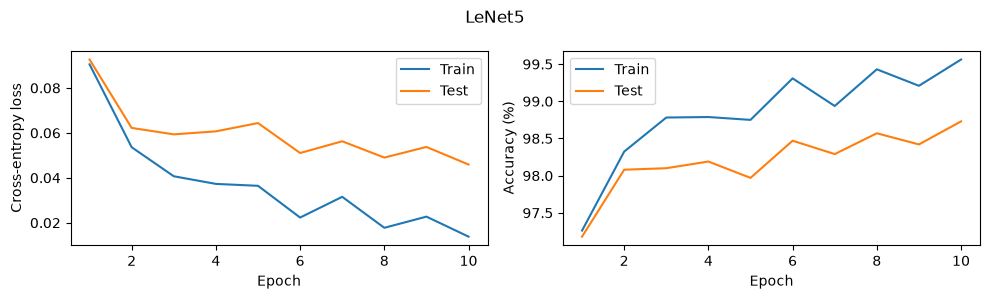

,epoch,train_loss,eval_loss,train_accuracy,eval_accuracy
0,1,0.0716,0.0724,97.6717,97.58
1,2,0.0456,0.0511,98.6133,98.42
2,3,0.0354,0.0391,98.9117,98.77
3,4,0.0315,0.0375,98.9900,98.81
4,5,0.0306,0.0412,99.0250,98.70
5,6,0.0292,0.0396,99.1183,98.62
6,7,0.0227,0.0332,99.2917,98.89
7,8,0.0222,0.0374,99.3067,98.89
8,9,0.0232,0.0419,99.2450,98.82
9,10,0.0162,0.0328,99.4567,99.01


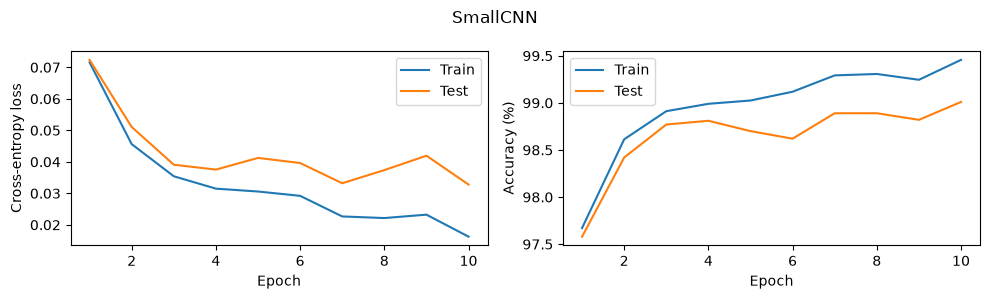

In [15]:
def plot_history(history, name, eval_name, filename):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].plot(history.epoch, history.train_loss, label='Train')
    axes[0].plot(history.epoch, history.eval_loss, label=eval_name)
    axes[1].plot(history.epoch, history.train_accuracy, label='Train')
    axes[1].plot(history.epoch, history.eval_accuracy, label=eval_name)
    axes[0].set_ylabel('Cross-entropy loss')
    axes[1].set_ylabel('Accuracy (%)')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.legend()
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(output_path / filename, dpi=160)
    plt.show()

for name in q2_results:
    display(q2_results[name].round(4))
    plot_history(q2_results[name], name, 'Test', f'q2_{name}_curves.png')


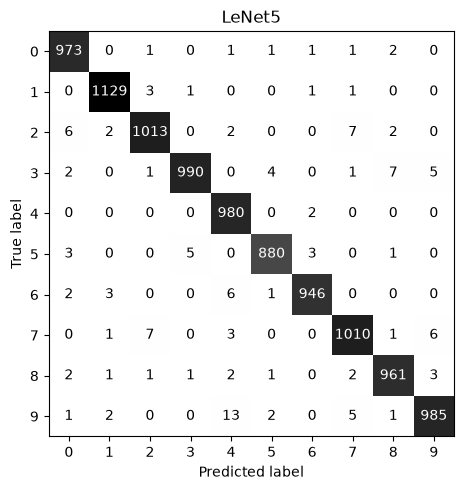

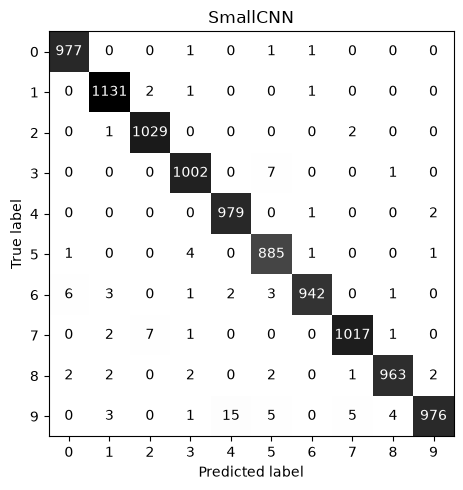

In [12]:
# Added comparison display
# Display both test confusion matrices
q2_matrices = {}
for name, model in q2_models.items():
    loss, accuracy, labels, predictions = evaluate(model, testloader, nn.CrossEntropyLoss())
    matrix = confusion_matrix(labels, predictions, labels=list(range(10)))
    q2_matrices[name] = matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(matrix, display_labels=list(range(10))).plot(
        ax=ax, cmap='Greys', colorbar=False, values_format='d')
    ax.set_title(name)
    fig.tight_layout()
    fig.savefig(output_path / f'q2_{name}_confusion.png', dpi=160)
    plt.show()


In [13]:
rows = []
for name in q2_results:
    last = q2_results[name].iloc[-1]
    count = sum(p.numel() for p in q2_models[name].parameters())
    rows.append([name, count, last.train_accuracy, last.eval_accuracy,
                 last.train_loss, last.eval_loss, q2_times[name]])
q2_summary = pd.DataFrame(rows, columns=[
    'Model', 'Parameters', 'Train accuracy (%)', 'Test accuracy (%)',
    'Train loss', 'Test loss', 'Seconds'])
display(q2_summary.round(4))
q2_summary.to_csv(output_path / 'q2_summary.csv', index=False)
delta = q2_results['SmallCNN'].iloc[-1].eval_accuracy - q2_results['LeNet5'].iloc[-1].eval_accuracy
display(Markdown(f'SmallCNN minus LeNet5 test accuracy is {delta:.2f} percentage points.'))
for name, matrix in q2_matrices.items():
    errors = matrix.copy()
    np.fill_diagonal(errors, 0)
    actual, predicted = np.unravel_index(errors.argmax(), errors.shape)
    if errors.max() > 0:
        print(f'{name}: largest error count is digit {actual} predicted as {predicted}, '
              f'{errors[actual, predicted]} images.')


,Model,Parameters,Train accuracy (%),Test accuracy (%),Train loss,Test loss,Seconds
0,LeNet5,61706,99.3967,98.67,0.0174,0.0494,239.0422
1,SmallCNN,45190,99.4567,99.01,0.0162,0.0328,252.1917


SmallCNN minus LeNet5 test accuracy is 0.34 percentage points.

LeNet5: largest error count is digit 9 predicted as 4, 13 images.
SmallCNN: largest error count is digit 9 predicted as 4, 15 images.


## QUESTION 3
### Important parts of code

In [20]:
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.datasets.utils import download_and_extract_archive

data_path = Path('data')
hymen_path = data_path / 'hymenoptera_data'
if not hymen_path.exists():
    download_and_extract_archive(
        'https://download.pytorch.org/tutorial/hymenoptera_data.zip',
        download_root=str(data_path))
assert (hymen_path / 'train').is_dir()
assert (hymen_path / 'val').is_dir()
weights = ResNet18_Weights.IMAGENET1K_V1
epochs = 25
batch_size = 4


100%|██████████| 47.3M/47.3M [00:29<00:00, 1.58MB/s]


In [ ]:
# Question 3 tutorial preprocessing
# https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
trainset = torchvision.datasets.ImageFolder(hymen_path / 'train', train_transform)
train_eval_set = torchvision.datasets.ImageFolder(hymen_path / 'train', eval_transform)
valset = torchvision.datasets.ImageFolder(hymen_path / 'val', eval_transform)
assert trainset.class_to_idx == valset.class_to_idx
class_names = trainset.classes
train_eval_loader = torch.utils.data.DataLoader(
    train_eval_set, batch_size=batch_size, shuffle=False, num_workers=0)
valloader = torch.utils.data.DataLoader(
    valset, batch_size=batch_size, shuffle=False, num_workers=0)
print('Classes:', class_names)
print('Train:', len(trainset), 'Validation:', len(valset))
#--------------------------------------


## QUESTION 3
### Important parts of code
[PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html). 




| Method | What learns |
|---|---|
| Fine-tuning | All ResNet18 parameters, including the new two-class layer |
| Feature extraction | Only the new two-class layer's parameters |

Both methods start from ImageNet1K weights and run for 25 epochs. The two output classes are ants and bees.

In [26]:
#---------------copied from tutorial


import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.backends.cudnn as cudnn
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
from PIL import Image
from tempfile import TemporaryDirectory

cudnn.benchmark = True
plt.ion()   # interactive mode
#----------end----------------


In [27]:
# Added dataset download
from pathlib import Path
from torchvision.datasets.utils import download_and_extract_archive
import pandas as pd
from IPython.display import display, Markdown
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

output_path = Path('results')
output_path.mkdir(exist_ok=True)
if not Path('data/hymenoptera_data').exists():
    download_and_extract_archive(
        'https://download.pytorch.org/tutorial/hymenoptera_data.zip',
        download_root='data')


In [28]:
#---------------copied from tutorial
# Data augmentation and normalization for training
# Just normalization for validation
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}
#----------end----------------


In [29]:
#---------------copied from tutorial
data_dir = 'data/hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}
#----------end----------------


In [30]:

# Tutorial code
dataloaders = {}
for phase in ['train', 'val']:
    dataloaders[phase] = torch.utils.data.DataLoader(
        image_datasets[phase], batch_size=4,
        shuffle=True, num_workers=4)


In [31]:
#---------------copied from tutorial
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

# We want to be able to train our model on an `accelerator <https://pytorch.org/docs/stable/torch.html#accelerators>`__
# such as CUDA, MPS, MTIA, or XPU. If the current accelerator is available, we will use it. Otherwise, we use the CPU.

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")
#----------end----------------


Using cuda device


Training uses random crops and flips. 
Validation uses a fixed center crop. 
Both use 224 by 224 RGB images and ImageNet normalization.
The folder called `val` is a validation set, not an independent test set. 
The notebook prints the actual image counts.
The added loader cell uses 4 workers . Batch size 4.

In [32]:
# Added dataset counts
print('Classes:', class_names)
print('Images:', dataset_sizes)

Classes: ['ants', 'bees']
Images: {'train': 244, 'val': 153}


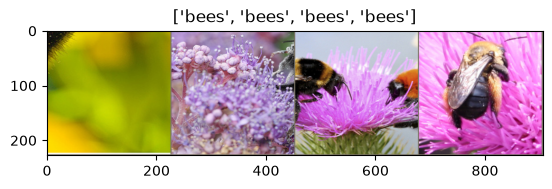

In [33]:
#---------------copied from tutorial
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])
#----------end----------------


In [34]:
#---------------copied from tutorial
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    # Create a temporary directory to save training checkpoints
    with TemporaryDirectory() as tempdir:
        best_model_params_path = os.path.join(tempdir, 'best_model_params.pt')
    
        torch.save(model.state_dict(), best_model_params_path)
        best_acc = 0.0

        for epoch in range(num_epochs):
            print(f'Epoch {epoch}/{num_epochs - 1}')
            print('-' * 10)

            # Each epoch has a training and validation phase
            for phase in ['train', 'val']:
                if phase == 'train':
                    model.train()  # Set model to training mode
                else:
                    model.eval()   # Set model to evaluate mode

                running_loss = 0.0
                running_corrects = 0

                # Iterate over data.
                for inputs, labels in dataloaders[phase]:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    # zero the parameter gradients
                    optimizer.zero_grad()

                    # forward
                    # track history if only in train
                    with torch.set_grad_enabled(phase == 'train'):
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        loss = criterion(outputs, labels)

                        # backward + optimize only if in training phase
                        if phase == 'train':
                            loss.backward()
                            optimizer.step()

                    # statistics
                    running_loss += loss.item() * inputs.size(0)
                    running_corrects += torch.sum(preds == labels.data)
                if phase == 'train':
                    scheduler.step()

                epoch_loss = running_loss / dataset_sizes[phase]
                epoch_acc = running_corrects.double() / dataset_sizes[phase]

                print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

                # deep copy the model
                if phase == 'val' and epoch_acc > best_acc:
                    best_acc = epoch_acc
                    torch.save(model.state_dict(), best_model_params_path)

            print()

        time_elapsed = time.time() - since
        print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
        print(f'Best val Acc: {best_acc:4f}')

        # load best model weights
        model.load_state_dict(torch.load(best_model_params_path, weights_only=True))
    return model
#----------end----------------


In [35]:
#---------------copied from tutorial
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)
#----------end----------------


#### 3(a)
The pretrained classifier has 1000 outputs. Its replacement has two outputs and $512\times2+2=1026$ parameters.
SGD updates all parameters. The learning rate starts at 0.001 and is multiplied by 0.1 every seven epochs.

In [36]:
# Added repeatable initialization
torch.manual_seed(42)


In [37]:
#---------------copied from tutorial
model_ft = models.resnet18(weights='IMAGENET1K_V1')
num_ftrs = model_ft.fc.in_features
# Here the size of each output sample is set to 2.
# Alternatively, it can be generalized to ``nn.Linear(num_ftrs, len(class_names))``.
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 7 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)
#----------end----------------


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\asus/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:09<00:00, 4.88MB/s]


In [38]:
# Added timing
torch.manual_seed(42)
fine_start = time.time()

In [39]:
#---------------copied from tutorial
model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler,
                       num_epochs=25)
#----------end----------------


Epoch 0/24
----------
train Loss: 0.8033 Acc: 0.6189
val Loss: 0.6055 Acc: 0.7190

Epoch 1/24
----------
train Loss: 0.4234 Acc: 0.8197
val Loss: 0.2615 Acc: 0.9020

Epoch 2/24
----------
train Loss: 0.5462 Acc: 0.7992
val Loss: 0.3600 Acc: 0.8627

Epoch 3/24
----------
train Loss: 0.5490 Acc: 0.7951
val Loss: 0.3619 Acc: 0.8693

Epoch 4/24
----------
train Loss: 0.3900 Acc: 0.8238
val Loss: 0.6009 Acc: 0.8235

Epoch 5/24
----------
train Loss: 0.5046 Acc: 0.8320
val Loss: 0.2338 Acc: 0.8889

Epoch 6/24
----------
train Loss: 0.4835 Acc: 0.8115
val Loss: 0.6108 Acc: 0.8170

Epoch 7/24
----------
train Loss: 0.3860 Acc: 0.8607
val Loss: 0.2178 Acc: 0.9150

Epoch 8/24
----------
train Loss: 0.3649 Acc: 0.8770
val Loss: 0.2243 Acc: 0.9150

Epoch 9/24
----------
train Loss: 0.2219 Acc: 0.9057
val Loss: 0.1838 Acc: 0.9150

Epoch 10/24
----------
train Loss: 0.2949 Acc: 0.8811
val Loss: 0.2168 Acc: 0.9150

Epoch 11/24
----------
train Loss: 0.3090 Acc: 0.8648
val Loss: 0.1948 Acc: 0.9216

Ep

In [40]:
# Added saved result
fine_seconds = time.time() - fine_start
torch.save(model_ft.state_dict(), output_path / 'q3_fine_best.pt')


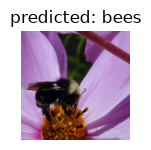

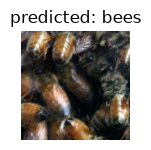

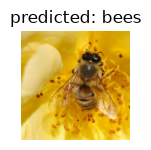

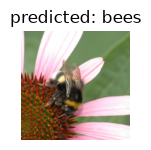

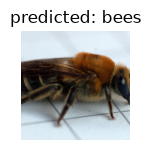

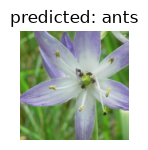

In [41]:
#---------------copied from tutorial
visualize_model(model_ft)
#----------end----------------
